# IS630: Green Light for an Indie Studio
## Notebook 03: AQ2, Can We Predict How Successful a Game Will Be?

> **AI Assistance Declaration**:
> An AI assistant wrote the code and drafted the model specifications at the group's direction, and subsequently drafted the labelled interpretations and revised explanatory prose. Group members must review these additions and record the assistance in the group's GenAI declaration; these interpretations are not independently student-authored.

**AQ2** (group wording): *Can we predict how successful a game will be? We study if, using the available data, we can build a model that holds some predictive power in predicting success.*

Success is measured by the completion ratio chosen in AQ1 (notebook 01): median Steam playtime divided by HowLongToBeat main-story hours. The target is its log, to express multiplicative differences additively. The saved diagnostics below show that appreciable negative skew remains after this transformation. Two models are fitted on the same predictors and compared against a baseline on held-out validation games:

| Section | Content |
|---|---|
| 1 | The modelling sample and the target |
| 2 | Frequentist model: OLS on the log ratio, standard errors clustered by developer |
| 3 | Bayesian model: hierarchical regression with developer effects and HowLongToBeat poll noise |
| 4 | Prior sensitivity |
| 5 | The two models' estimates side by side |
| 6 | Is there predictive signal? Validation comparison against a baseline |

**Reads:** `data/processed/02_train.parquet`, `data/processed/02_validation.parquet`, `data/processed/02_feature_spec.json`
**Writes:** `data/interim/03_aq2_predictions.parquet`, tables `outputs/tables/03_aq2_*.csv`, figures `outputs/figures/03_aq2_*.png`, traces in `outputs/models` (gitignored)

The validation set is the 20% split made in notebook 02 from training data. The test holdout from notebook 00 is never loaded here.

*Written by AI Assistant*: interpretations refer to the saved notebook outputs and accompanying AQ2 tables. These outputs were not regenerated during this edit because the required Parquet inputs are absent from this checkout. The fitted models, thresholds and prediction code are unchanged. This notebook evaluates the completion-ratio proxy, not sales, profit or a measured proportion of players finishing a game.

## Setup
*Code: Generated by AI Assistant*

In [1]:
import sys
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.outliers_influence import variance_inflation_factor
import pymc as pm
import arviz as az

sys.path.insert(0, str(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").exists()) / "src"))
from is630 import config
from is630.models import COMPLETION_PRIORS, SAMPLE_KW, completion_sample, completion_model

for d in (config.FIGURES, config.TABLES, config.MODELS):
    d.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 200)
rng = np.random.default_rng(config.SEED)

def save_fig(fig, name):
    """Write a figure to outputs/figures at 300 dpi."""
    fig.savefig(config.FIGURES / f"{name}.png", dpi=300, bbox_inches="tight")

df_train = pd.read_parquet(config.PROCESSED / "02_train.parquet")
df_val = pd.read_parquet(config.PROCESSED / "02_validation.parquet")
with open(config.PROCESSED / "02_feature_spec.json", encoding="utf-8") as f:
    feature_spec = json.load(f)
FEATURES = feature_spec["model_features"]
assert set(df_train["steam_appid"]).isdisjoint(df_val["steam_appid"])
print(f"rows in: {len(df_train):,} development training, {len(df_val):,} validation")
print(f"predictors from notebook 02: {len(FEATURES)}")
print(f"pymc {pm.__version__}, arviz {az.__version__}")

g++ not available, if using conda: `conda install gxx`


rows in: 4,224 development training, 1,057 validation
predictors from notebook 02: 31
pymc 6.3.2, arviz 1.3.0


## 1. The modelling sample and the target
*Code: Generated by AI Assistant*

*Written by AI Assistant*: the sample is every game with `flag_completion_model`, the eligibility rule fixed in notebook 02 (story-driven, matched, a positive completion ratio, at least 50 Steam reviews, at least 5 HowLongToBeat main-story polls). The target is `log_ratio = log(completion_ratio)`. A log ratio of 0 means the median player's playtime equals the main-story time.

Continuous predictors are standardised with the development-training mean and standard deviation, so their coefficients are per standard deviation. Binary predictors stay 0/1. Both models use the same matrix, so their coefficients are on the same scale.

Each game's developer is its first listed developer. Games with no developer listed get a group of their own.

In [2]:
# Sample, target and standardisation live in src/is630/models.py so notebook 04 uses the same ones
s = completion_sample(df_train, df_val, FEATURES)
train, val, X_train, X_val, y_train, y_val = s.train, s.val, s.X_train, s.X_val, s.y_train, s.y_val
binary, continuous = s.binary, s.continuous

dev_counts = train["developer_group"].value_counts()
val_seen = val["developer_group"].isin(dev_counts.index)
print(f"rows in: {len(df_train):,} / {len(df_val):,}; rows out (completion model sample): {len(train):,} train, {len(val):,} validation")
print(f"predictors: {len(continuous)} continuous (standardised), {len(binary)} binary")
print(f"developers in training: {len(dev_counts):,}, of which {int((dev_counts >= 2).sum()):,} have 2+ games "
      f"({int(dev_counts[dev_counts >= 2].sum()):,} games)")
print(f"validation games whose developer appears in training: {int(val_seen.sum()):,} ({val_seen.mean() * 100:.1f}%)")

summary = pd.DataFrame({
    "train": train["log_ratio"].describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]),
    "validation": val["log_ratio"].describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]),
}).T
summary["skew"] = [train["log_ratio"].skew(), val["log_ratio"].skew()]
summary["median_polls"] = [train["hltb_main_story_polled"].median(), val["hltb_main_story_polled"].median()]
summary.round(3)

rows in: 4,224 / 1,057; rows out (completion model sample): 1,927 train, 482 validation
predictors: 6 continuous (standardised), 25 binary
developers in training: 1,322, of which 273 have 2+ games (878 games)
validation games whose developer appears in training: 215 (44.6%)


,count,mean,std,min,5%,25%,50%,75%,95%,max,skew,median_polls
train,1927.0,-0.386,1.088,-6.516,-2.203,-0.889,-0.238,0.219,1.145,3.283,-0.945,27.0
validation,482.0,-0.369,1.122,-5.704,-2.436,-0.889,-0.172,0.304,0.932,4.535,-0.760,23.0


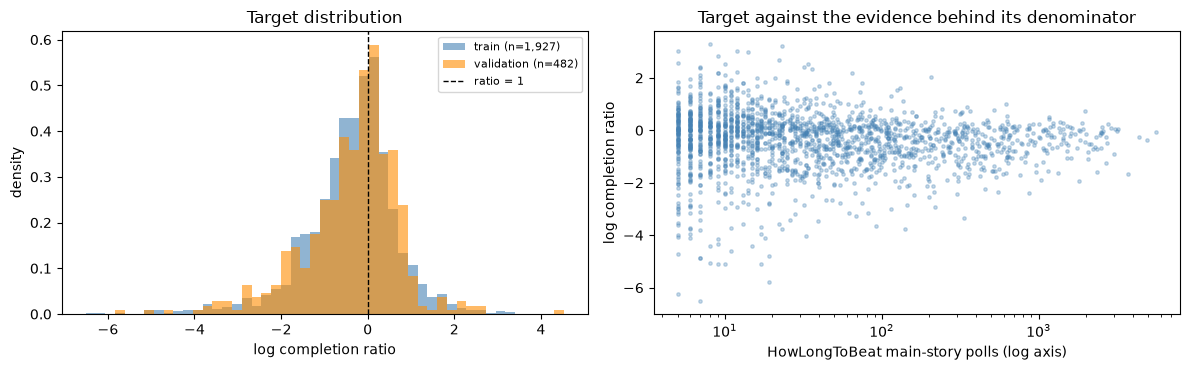

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
bins = np.linspace(min(y_train.min(), y_val.min()), max(y_train.max(), y_val.max()), 50)
axes[0].hist(y_train, bins=bins, density=True, alpha=0.6, label=f"train (n={len(y_train):,})", color="steelblue")
axes[0].hist(y_val, bins=bins, density=True, alpha=0.6, label=f"validation (n={len(y_val):,})", color="darkorange")
axes[0].axvline(0, color="black", linestyle="--", linewidth=1, label="ratio = 1")
axes[0].set_xlabel("log completion ratio"); axes[0].set_ylabel("density"); axes[0].legend(fontsize=8)
axes[0].set_title("Target distribution")
axes[1].scatter(train["hltb_main_story_polled"], train["log_ratio"], s=6, alpha=0.3, color="steelblue")
axes[1].set_xscale("log"); axes[1].set_xlabel("HowLongToBeat main-story polls (log axis)")
axes[1].set_ylabel("log completion ratio"); axes[1].set_title("Target against the evidence behind its denominator")
plt.tight_layout()
save_fig(fig, "03_aq2_target")
plt.show()

### Interpretation: The modelling sample

The models use 1,927 training games and 482 validation games that pass the completion-model thresholds. Both training and validation sets have similar mean log ratios (-0.386 and -0.369) and standard deviations (1.088 and 1.122). Approximately, their median ratios are 0.788 and 0.842 after exponentiating the displayed log medians. Both of the distributions are negatively skewed (-0.945 and -0.760), which means that the log transformations do not make them normal. 

Training consists of 1,322 developers. Of these, 273 have at least two games and account for 878 training games, so treating every game as independent would ignore meaningful grouping. In validation, there are 215 games (44.6%) have developers seen in training while the remaining 267 have unseen developers.

The target plot shows a larger spread with low HLTB poll counts, including outliers. The median poll count is 27 in training and 23 in validation. This pattern motivates allowing noise to vary with poll count, however it does not establish that HLTB sampling error is its sole cause. All results remain conditional on the matched, sufficiently reviewed and sufficiently polled population.

## 2. Frequentist model: OLS on the log completion ratio
*Code: Generated by AI Assistant*

*Written by AI Assistant*: ordinary least squares on `log_ratio` with every predictor from notebook 02. Games from the same developer are not independent, so standard errors are clustered by developer. A coefficient `b` changes the conditional mean log ratio by `b`; exponentiating gives a multiplier of `exp(b)` for the conditional geometric mean ratio for a one-unit change in a binary predictor or a one-standard-deviation change in a continuous one. That multiplier is reported as the effect size. With this many predictors tested at once, p-values are also adjusted with Benjamini-Hochberg (`q_bh`).

Two limits apply to every coefficient below. `steam_price` is the price at scrape time, not the launch price. The numerator of the ratio, SteamSpy's median playtime, is an estimate from public profiles with no count of the profiles behind it, so its uncertainty cannot be modelled. OLS gives each game equal weight, and its observation intervals use a common residual variance. The Bayesian model in section 3 relaxes that.

In [4]:
Xc_train = sm.add_constant(X_train, has_constant="add")
Xc_val = sm.add_constant(X_val, has_constant="add")[Xc_train.columns]
assert np.linalg.matrix_rank(Xc_train.to_numpy()) == Xc_train.shape[1], "design matrix is rank-deficient"
clusters = pd.factorize(train["developer_group"])[0]

ols = sm.OLS(y_train, Xc_train).fit(cov_type="cluster", cov_kwds={"groups": clusters})
ci = ols.conf_int(alpha=0.05)
ols_table = pd.DataFrame({
    "coef": ols.params, "cluster_se": ols.bse, "ci_low": ci[0], "ci_high": ci[1],
    "ratio_multiplier": np.exp(ols.params), "p": ols.pvalues,
})
ols_table["q_bh"] = np.nan
ols_table.loc[FEATURES, "q_bh"] = multipletests(ols_table.loc[FEATURES, "p"], method="fdr_bh")[1]
ols_table.to_csv(config.TABLES / "03_aq2_ols_coefficients.csv")

print(f"n = {int(ols.nobs):,}, developer clusters = {len(np.unique(clusters)):,}")
print(f"in-sample R^2 = {ols.rsquared:.3f}, adjusted R^2 = {ols.rsquared_adj:.3f}, residual SD = {np.sqrt(ols.scale):.3f}")
print(f"predictors with q_bh < 0.05: {int((ols_table['q_bh'] < 0.05).sum())} of {len(FEATURES)}")
ols_table.round(4)

n = 1,927, developer clusters = 1,322
in-sample R^2 = 0.166, adjusted R^2 = 0.152, residual SD = 1.002
predictors with q_bh < 0.05: 10 of 31


,coef,cluster_se,ci_low,ci_high,ratio_multiplier,p,q_bh
const,-0.9426,0.2021,-1.3387,-0.5465,0.3896,0.0000,NaN
feature_log_price,0.0301,0.0403,-0.0489,0.1092,1.0306,0.4547,0.5639
flag_free_to_play,0.2259,0.1556,-0.0791,0.5308,1.2534,0.1466,0.2767
steam_years_since_release,-0.2459,0.0361,-0.3167,-0.1752,0.7820,0.0000,0.0000
flag_q4_release,0.0481,0.0508,-0.0516,0.1477,1.0492,0.3446,0.4645
steam_mac,0.0822,0.0656,-0.0463,0.2108,1.0857,0.2100,0.3593
steam_linux,0.0245,0.0783,-0.1289,0.1779,1.0248,0.7540,0.8061
feature_log_language_count_imputed,-0.0233,0.0339,-0.0898,0.0433,0.9770,0.4931,0.5880
feature_log_audio_language_count,0.1007,0.0498,0.0032,0.1983,1.1060,0.0430,0.1112
flag_has_full_audio,-0.1178,0.1052,-0.3241,0.0884,0.8889,0.2629,0.4075


### Interpretation: OLS coefficients

The OLS model explains 16.6% of the training variation in log completion ratio (adjusted R-squared 15.2%). Its residual standard deviation is 1.002 log units. This is a description of the fitted sample.

Ten of the 31 predictors have Benjamini-Hochberg-adjusted `q_bh < 0.05`. The estimated ratio multipliers are shown below. The displayed confidence intervals in the coefficient table remain ordinary 95% developer-clustered intervals. These have not been adjusted for multiple testing.

| Predictor | Ratio multiplier | Comparison |
|---|---:|---|
| Game age | 0.782 | One training SD higher |
| Log achievement count | 0.778 | One training SD higher, with achievement presence held fixed |
| Achievement presence | 1.752 | Formal indicator contrast, with log achievement count held fixed |
| Controller support | 0.828 | Indicator 0 to 1 |
| Trading cards | 1.371 | Indicator 0 to 1 |
| VR | 0.730 | Indicator 0 to 1 |
| Casual genre | 1.289 | Indicator 0 to 1 |
| Strategy genre | 0.694 | Indicator 0 to 1 |
| RPG genre | 0.741 | Indicator 0 to 1 |
| Early Access genre | 2.006 | Indicator 0 to 1 |

These are adjusted associations and not causal effects. Achievement presence and count are linked, therefore the indicator multiplier alone is not the predicted change from adding achievements to a game. Genres can also overlap. Indie has an unadjusted interval that excludes zero, but its adjusted `q_bh` of 0.0512 falls just above the stated threshold.

Price has a multiplier of 1.031, an interval for its coefficient that crosses zero, and `q_bh = 0.5639`. There is no clear adjusted price association in this model. All these estimates concern a ratio based on estimated SteamSpy playtime, not a player's probability of finishing.

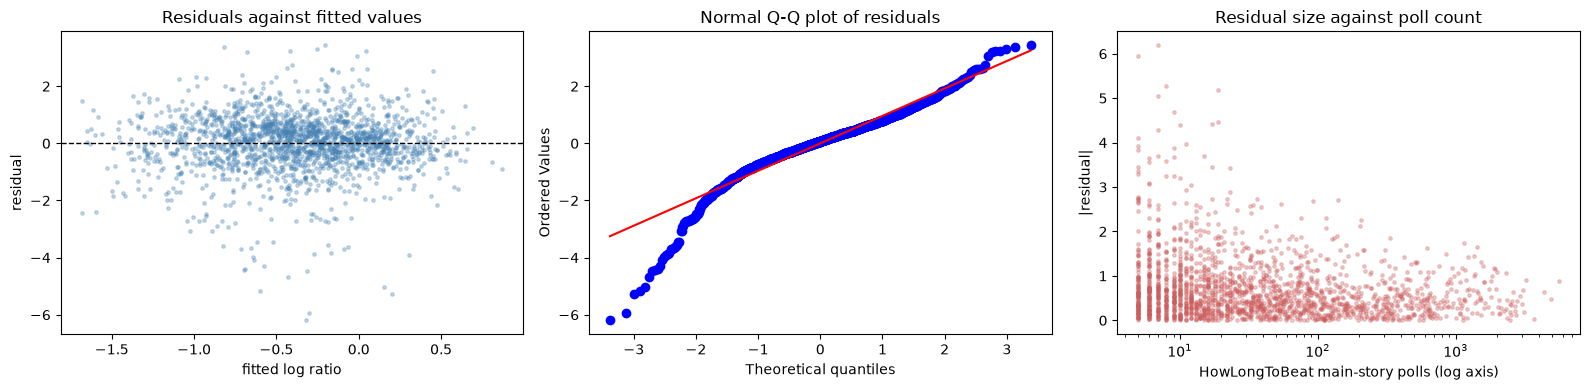

Residual SD by HowLongToBeat poll band:
        games  resid_sd
5-10      502     1.290
11-30     510     1.052
31-100    422     0.816
100+      493     0.662

residual skew = -1.046, excess kurtosis = 4.576
largest VIF = 6.18 (feature_log_achievements); predictors with VIF > 5: 2


,VIF
feature_log_achievements,6.18
flag_has_achievements,5.54
feature_log_audio_language_count,4.78
flag_has_full_audio,3.96
cat_multiplayer,2.68
cat_coop,2.45
steam_years_since_release,1.98
feature_log_price,1.96
steam_mac,1.87
steam_linux,1.79


In [5]:
resid = ols.resid
fitted = ols.fittedvalues
vif = pd.Series([variance_inflation_factor(Xc_train.to_numpy(), i) for i in range(1, Xc_train.shape[1])],
                index=FEATURES, name="VIF").sort_values(ascending=False)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].scatter(fitted, resid, s=6, alpha=0.3, color="steelblue")
axes[0].axhline(0, color="black", linestyle="--", linewidth=1)
axes[0].set_xlabel("fitted log ratio"); axes[0].set_ylabel("residual"); axes[0].set_title("Residuals against fitted values")
stats.probplot(resid, dist="norm", plot=axes[1])
axes[1].set_title("Normal Q-Q plot of residuals")
polls = train["hltb_main_story_polled"].to_numpy()
axes[2].scatter(polls, np.abs(resid), s=6, alpha=0.3, color="indianred")
axes[2].set_xscale("log")
axes[2].set_xlabel("HowLongToBeat main-story polls (log axis)"); axes[2].set_ylabel("|residual|")
axes[2].set_title("Residual size against poll count")
plt.tight_layout()
save_fig(fig, "03_aq2_ols_diagnostics")
plt.show()

band = pd.cut(polls, [0, 10, 30, 100, np.inf], labels=["5-10", "11-30", "31-100", "100+"])
print("Residual SD by HowLongToBeat poll band:")
print(pd.Series(resid).groupby(band, observed=True).agg(games="size", resid_sd="std").round(3).to_string())
print(f"\nresidual skew = {stats.skew(resid):.3f}, excess kurtosis = {stats.kurtosis(resid):.3f}")
print(f"largest VIF = {vif.iloc[0]:.2f} ({vif.index[0]}); predictors with VIF > 5: {int((vif > 5).sum())}")
vif.to_csv(config.TABLES / "03_aq2_vif.csv")
vif.round(2).to_frame()

### Interpretation: OLS diagnostics

The residuals are centred near zero, however there is a significant number of games with large negative errors. The Q-Q plot shows a number of clear departures from the reference line, particularly in the lower end.  Residual skew of -1.046 and excess kurtosis of 4.576 also show that a normal error distribution is a poor description of the tails.

The residual spread falls as HLTB poll counts increase. Residual standard deviation is 1.290 for games with 5-10 polls, then 1.052 for 11-30, 0.816 for 31-100, and 0.662 above 100. Treating all games as equally precise misses a clear feature of the data as a result of this. Clustering standard errors by developer helps with coefficient uncertainty, although it does not fix the normal, constant-variance assumptions used for the OLS prediction intervals.

log achievement count (6.18) and achievement presence (5.54) have the highest VIF counts. These variables have overlapping information, making their separate coefficients more difficult to estimate, so they must be interpreted together.  OLS remains useful as a comparison, but the validation results are needed to judge how well its predictions and intervals work.

### Influence diagnostics
*Code: Generated by AI Assistant, adapted from Sheen Fernando's diagnostics in `notebooks/archive/03_aq2_reception_models.ipynb`*

*Written by AI Assistant*: Cook's distance measures how much each training game moves the OLS fit. Games above the common screening cutoff of 4/n are flagged. Two refits test whether the coefficients rest on a few games: one without the flagged games, and one without games above the training 99th percentile of the log ratio, Sheen's extreme-value rule. Each refit keeps the clustered standard errors and is scored on the same validation games. A coefficient shift is measured in clustered standard errors of the full fit.

In [6]:
infl = ols.get_influence()
cooks = infl.cooks_distance[0]
COOKS_CUTOFF = 4 / len(y_train)
flagged = cooks > COOKS_CUTOFF
top_cut = np.quantile(y_train, 0.99)

influence_table = train[["steam_name", "completion_ratio", "hltb_main_story", "hltb_main_story_polled"]].assign(
    log_ratio=y_train, cooks_distance=cooks, leverage=infl.hat_matrix_diag,
    studentised_resid=infl.resid_studentized_internal)
print(f"Cook's distance cutoff 4/n = {COOKS_CUTOFF:.5f}; flagged games: {int(flagged.sum())} of {len(y_train):,}")
display(influence_table.nlargest(10, "cooks_distance").round(4))

def refit(keep):
    # Dropping games can leave a rare binary predictor with no 1s; such a column is dropped from that refit.
    X = Xc_train[keep]
    X = X[[c for c in X if c == "const" or X[c].nunique() > 1]]
    assert np.linalg.matrix_rank(X.to_numpy()) == X.shape[1], "refit design matrix is rank-deficient"
    return sm.OLS(y_train[keep], X).fit(cov_type="cluster", cov_kwds={"groups": clusters[keep]})

fits = {"all games": ols, "without Cook's flagged": refit(~flagged), "without top 1% log ratio": refit(y_train <= top_cut)}
for name, f in fits.items():
    print(f"{name}: constant in the refit sample, dropped: {sorted(set(FEATURES) - set(f.params.index)) or 'none'}")
robust = pd.DataFrame({name: f.params.reindex(FEATURES) for name, f in fits.items()})
for name in list(fits)[1:]:
    robust[f"shift_in_se, {name}"] = (robust[name] - robust["all games"]) / ols.bse[FEATURES]
    ci_r = fits[name].conf_int().reindex(FEATURES)
    robust[f"excludes_0, {name}"] = ((ci_r[0] > 0) | (ci_r[1] < 0)).where(ci_r[0].notna())
robust.insert(1, "excludes_0, all games", (ci.loc[FEATURES, 0] > 0) | (ci.loc[FEATURES, 1] < 0))
robust.to_csv(config.TABLES / "03_aq2_influence_refits.csv")

fit_summary = pd.DataFrame({name: {
    "training games": int(f.nobs),
    "predictors": len(f.params) - 1,
    "validation RMSE": np.sqrt(np.mean((y_val - f.predict(Xc_val[f.params.index])) ** 2)),
    "intervals excluding 0": int(robust[f"excludes_0, {name}"].eq(True).sum()),
    "sign changes vs all games": int((np.sign(robust[name]) != np.sign(robust["all games"]))[robust[name].notna()].sum()),
} for name, f in fits.items()}).T
print(fit_summary.to_string())
shift_cols = [c for c in robust if c.startswith("shift_in_se")]
robust.reindex(robust[shift_cols].abs().max(axis=1).sort_values(ascending=False).index).head(12).round(3)

Cook's distance cutoff 4/n = 0.00208; flagged games: 101 of 1,927


,steam_name,completion_ratio,hltb_main_story,hltb_main_story_polled,log_ratio,cooks_distance,leverage,studentised_resid
172,Nancy Drew® Dossier: Resorting to Danger!,2.0586,3.70,6.0,0.7220,0.0291,0.5064,0.9525
2488,Cube Escape Collection,0.6483,7.25,53.0,-0.4334,0.0291,0.5064,-0.9525
4220,OZMAFIA!!,0.0015,11.26,7.0,-6.5156,0.0181,0.0147,-6.2285
2487,Maitetsu,0.0019,17.41,5.0,-6.2582,0.0164,0.0145,-5.9854
2607,NGU IDLE,0.0157,1591.65,9.0,-4.1517,0.0144,0.0290,-3.9286
254,Desert Bus VR,0.0554,8.42,6.0,-2.8927,0.0123,0.0655,-2.3686
237,Midnight Carnival,6.9551,0.52,6.0,1.9395,0.0118,0.1601,1.4068
550,Mineko's Night Market,0.0063,18.42,8.0,-5.0619,0.0111,0.0126,-5.2895
3503,Tex Murphy: Martian Memorandum,0.0031,5.38,19.0,-5.7770,0.0110,0.0129,-5.1982
4128,Asdivine Hearts,0.0120,26.38,8.0,-4.4225,0.0107,0.0253,-3.6358


all games: constant in the refit sample, dropped: none
without Cook's flagged: constant in the refit sample, dropped: ['flag_missing_genre']
without top 1% log ratio: constant in the refit sample, dropped: none
                          training games  predictors  validation RMSE  intervals excluding 0  sign changes vs all games
all games                         1927.0        31.0         1.043720                   13.0                        0.0
without Cook's flagged            1826.0        30.0         1.055387                   13.0                        2.0
without top 1% log ratio          1907.0        31.0         1.044274                   14.0                        3.0


,all games,"excludes_0, all games",without Cook's flagged,without top 1% log ratio,"shift_in_se, without Cook's flagged","excludes_0, without Cook's flagged","shift_in_se, without top 1% log ratio","excludes_0, without top 1% log ratio"
cat_trading_cards,0.315,True,0.173,0.316,-2.205,True,0.016,True
flag_has_website,0.095,False,0.019,0.102,-1.234,False,0.114,False
genre_adventure,-0.025,False,0.052,0.000,1.144,False,0.374,False
genre_early_access,0.696,True,0.416,0.754,-1.137,True,0.235,True
steam_years_since_release,-0.246,True,-0.212,-0.234,0.943,True,0.334,True
feature_log_price,0.030,False,0.049,0.066,0.466,False,0.888,False
genre_indie,0.158,True,0.101,0.165,-0.861,True,0.095,True
genre_strategy,-0.365,True,-0.285,-0.365,0.848,True,0.006,True
cat_coop,-0.006,False,0.103,-0.021,0.757,False,-0.108,False
feature_log_language_count_imputed,-0.023,False,-0.048,-0.012,-0.725,False,0.323,False


### Interpretation: Influence diagnostics

Cook's distance flags 101 out of the 1,927 training games. The two most influential games consist of a leverage about 0.506 despite only moderate residuals. Other influential games have very low ratios and large negative residuals, often with few HLTB polls. This shows that an observation can be influential because its predictors are unusual, because its outcome is extreme, or both.

Removing flagged games leaves 1,826 observations. Missing genre indicator is dropped because it is constant. The trading-card coefficient falls from 0.315 to 0.173, a change of 2.205 full-fit clustered standard errors. Website, Adventure and Early Access also move by more than one standard error. Two coefficients change sign, and the audio-language-count interval now includes zero. These interval comparisons do not adjust for multiple testing.

The refits do not improve validation accuracy. RMSE rises from 1.0437 to 1.0554 after removing Cook's flagged games. Removing the top 1% of training log ratios leaves 1,907 games and gives an almost identical RMSE of 1.0443, despite three coefficient sign changes. The full model is therefore retained for the main comparison, with these refits showing where its estimates are sensitive.

## 3. Bayesian model: hierarchical regression with developer effects and poll noise
*Code: Generated by AI Assistant*

*Written by AI Assistant*: the same predictors and target, with two additions the OLS model lacks.

1. A random intercept per developer, partially pooled. A developer with one game is shrunk towards zero and a developer with many games keeps more of its own level. This replaces clustered standard errors as the way of handling developers.
2. A noise term that shrinks with the HowLongToBeat poll count. The model assumes that one component of log-ratio variance decreases in proportion to `1/n`, where `n` is the main-story poll count. The model gives each game its own noise level, `sqrt(sigma^2 + tau^2 / n)`, where `sigma` is noise that does not depend on `n` and `tau` scales the part that shrinks as `n` grows. `tau` is not purely HowLongToBeat report noise: poll count rises with a game's popularity, so anything else that gets more precise for popular games, such as SteamSpy's playtime estimate, loads onto it too. The numerator's uncertainty cannot be modelled directly, because SteamSpy gives no count behind its median playtime.

$$\log r_i \sim \text{Normal}\left(\mu_i,\ \sqrt{\sigma^2 + \tau^2 / n_i}\right), \qquad \mu_i = \alpha + x_i^\top \beta + u_{d[i]}, \qquad u_d = \sigma_d z_d$$

Priors, on standardised predictors:

| Parameter | Prior | Reading |
|---|---|---|
| intercept $\alpha$ | Normal(0, 1) | a typical ratio between about 0.14 and 7.4 |
| coefficients $\beta$ | Normal(0, 0.5) | a one-unit change rarely multiplies the ratio by more than about 2.7 |
| developer SD $\sigma_d$ | HalfNormal(0.5) | |
| residual SD $\sigma$ | HalfNormal(1) | |
| poll-scaled SD $\tau$ | HalfNormal(1) | noise that shrinks as $1/\sqrt{n}$ |
| $z_d$ | Normal(0, 1) | non-centred developer effects |

Sampling uses the NUTS sampler from numpyro (4 chains, 1,000 tuning and 1,000 kept draws each). A validation game whose developer is not in training gets a developer effect of zero, the population average.

For unseen developers, the current code also fixes this effect to zero when constructing predictive intervals. It therefore omits variation in a new developer's random intercept. The intervals include parameter uncertainty and poll-scaled observation noise, but do not integrate over all uncertainty for unseen developers. This limitation is retained explicitly when interpreting the saved coverage figures.

Sampling: [beta, intercept, log_ratio, sigma, sigma_dev, tau, z_dev]


prior predictive quantiles of the log ratio (1%, 5%, 50%, 95%, 99%): [-5.81 -4.    0.03  4.25  6.15]
observed training quantiles                                : [-4.01 -2.2  -0.24  1.14  2.08]


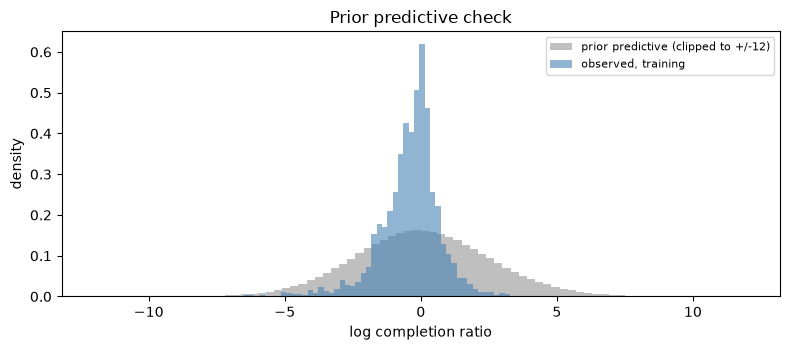

In [7]:
dev_levels, dev_train, dev_val = s.dev_levels, s.dev_train, s.dev_val
inv_polls_train, inv_polls_val = s.inv_polls_train, s.inv_polls_val

MAIN_PRIORS = COMPLETION_PRIORS  # values in the prior table above, kept in src/is630/models.py

def build_model(priors):
    # Model definition lives in src/is630/models.py, shared with notebook 04
    return completion_model(X_train, y_train, dev_train, inv_polls_train, len(dev_levels), priors)

bayes_model = build_model(MAIN_PRIORS)

# Prior predictive check: what the priors alone say about the log ratio
with bayes_model:
    prior_pred = pm.sample_prior_predictive(500, random_seed=config.SEED)
prior_draws = np.asarray(prior_pred["prior_predictive"]["log_ratio"]).ravel()
q = np.quantile(prior_draws, [0.01, 0.05, 0.5, 0.95, 0.99])
print("prior predictive quantiles of the log ratio (1%, 5%, 50%, 95%, 99%):", np.round(q, 2))
print("observed training quantiles                                :", np.round(np.quantile(y_train, [0.01, 0.05, 0.5, 0.95, 0.99]), 2))

fig, ax = plt.subplots(figsize=(8, 3.6))
clip = np.clip(prior_draws, -12, 12)
ax.hist(clip, bins=80, density=True, alpha=0.5, color="grey", label="prior predictive (clipped to +/-12)")
ax.hist(y_train, bins=50, density=True, alpha=0.6, color="steelblue", label="observed, training")
ax.set_xlabel("log completion ratio"); ax.set_ylabel("density"); ax.legend(fontsize=8)
ax.set_title("Prior predictive check")
plt.tight_layout()
save_fig(fig, "03_aq2_prior_predictive")
plt.show()

### Interpretation: Prior predictive check

Priors allow for a much wider range of ratios than the central part of the training data. The prior predictive median log ratio is 0.03, close to a ratio of one. Its 5th and 95th percentiles are -4.00 and 4.25, equivalent to ratios of about 0.018 and 70.1. The same training percentiles are -2.20 and 1.14, or roughly 0.111 and 3.13.

This indicates that priors are broad specifically for high ratios, and allow some very large playtime-to-duration values. This spread comes from the combined effects of the 31 predictors, intercept, developer effects and noise. It is not enough to show which prior contributes most by the plot alone. 

In [8]:
with bayes_model:
    idata = pm.sample(**SAMPLE_KW)

GLOBAL = ["intercept", "beta", "sigma", "tau", "sigma_dev"]

def diagnostics(trace):
    s = az.summary(trace, var_names=GLOBAL)
    z = az.summary(trace, var_names=["z_dev"])
    divergences = int(np.asarray(trace.sample_stats["diverging"]).sum())
    checks = pd.Series({
        "max r_hat (global)": float(s["r_hat"].max()),
        "max r_hat (developer z)": float(z["r_hat"].max()),
        "min ess_bulk (global)": float(s["ess_bulk"].min()),
        "min ess_tail (global)": float(s["ess_tail"].min()),
        "min ess_bulk (developer z)": float(z["ess_bulk"].min()),
        "divergences": divergences,
    })
    passed = (checks["max r_hat (global)"] < 1.01 and checks["max r_hat (developer z)"] < 1.01
              and checks["min ess_bulk (global)"] > 400 and checks["min ess_tail (global)"] > 400 and divergences == 0)
    return s, checks, passed

bayes_summary, bayes_checks, bayes_ok = diagnostics(idata)
bayes_summary.to_csv(config.TABLES / "03_aq2_bayes_summary.csv")
print(bayes_checks.round(3).to_string())
print(f"\nthresholds: r_hat < 1.01, ess_bulk and ess_tail > 400, zero divergences -> {'all met' if bayes_ok else 'NOT MET'}")
try:
    idata.to_netcdf(config.MODELS / "03_aq2_bayes_main.nc")
except Exception as e:  # saving the trace is a convenience, not part of the result
    print(f"trace not saved: {e}")
bayes_summary.loc[["intercept", "sigma", "tau", "sigma_dev"]]

NUTS[numpyro]: [intercept, beta, sigma_dev, z_dev, sigma, tau]


C:\Users\leesi\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


max r_hat (global)               1.004
max r_hat (developer z)          1.008
min ess_bulk (global)          940.917
min ess_tail (global)         1743.369
min ess_bulk (developer z)    2663.042
divergences                      0.000

thresholds: r_hat < 1.01, ess_bulk and ess_tail > 400, zero divergences -> all met
trace not saved: cannot write NetCDF files with format='NETCDF4' because none of the suitable backend libraries (netCDF4, h5netcdf) are installed


,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
intercept,-0.954,0.183,-1.2,-0.66,2602,2775,1.00,0.0036,0.0027
sigma,0.533,0.024,0.5,0.57,2240,2794,1.00,0.00051,0.00033
tau,3.064,0.129,2.9,3.3,3231,3130,1.00,0.0023,0.0019
sigma_dev,0.398,0.034,0.34,0.45,940,1743,1.00,0.0011,0.00054


### Interpretation: Bayesian convergence

The main Bayesian fit passes the sampling checks. Maximum R-hat is 1.004 for the global parameters and 1.008 for developer effects. The smallest global bulk and tail effective sample sizes are about 941 and 1,743, and the smallest developer bulk ESS is 2,663. There are no observed divergences. The results support using posterior draws, although they do not tell us whether the model describes the data well.

The posterior means are 0.533 for sigma, 3.064 for tau, and 0.398 for the developer standard deviation.Using these means in the noise formula gives an observation standard deviation of about 1.47 log units at five polls, 0.79 at 27 polls, and 0.61 at 100 polls. These are illustrative calculations rather than posterior intervals, and they exclude the developer effects. This shows how strongly the model allows uncertainty to increase for games with few polls.

Poll count is also related to popularity, and SteamSpy estimates may be more precise for popular games. The posterior predictive check below assesses how well the fitted model reproduces the data.

Sampling: [log_ratio]


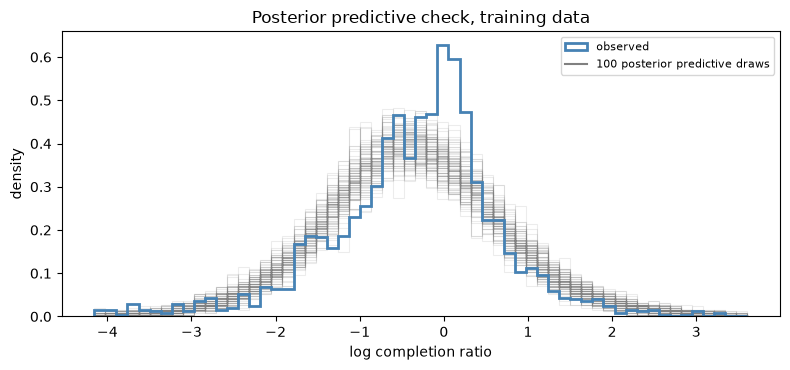

,observed,replicated_mean,replicated_5%,replicated_95%,share_rep_above_obs
statistic,,,,,
mean,-0.386,-0.375,-0.422,-0.335,0.65
sd,1.088,1.089,1.049,1.137,0.49
5th pct,-2.203,-2.132,-2.245,-2.029,0.90
95th pct,1.145,1.424,1.322,1.520,1.00
skew,-0.944,0.076,-0.039,0.195,1.00


In [9]:
with bayes_model:
    ppc = pm.sample_posterior_predictive(idata, random_seed=config.SEED, progressbar=False)
reps = np.asarray(ppc["posterior_predictive"]["log_ratio"]).reshape(-1, len(y_train))
pick = rng.choice(len(reps), size=100, replace=False)

def stat_table(observed, replicated):
    funcs = {"mean": np.mean, "sd": np.std, "5th pct": lambda a: np.quantile(a, 0.05),
             "95th pct": lambda a: np.quantile(a, 0.95), "skew": stats.skew}
    rows = []
    for name, f in funcs.items():
        obs = f(observed)
        rep = np.array([f(r) for r in replicated])
        rows.append({"statistic": name, "observed": obs, "replicated_mean": rep.mean(),
                     "replicated_5%": np.quantile(rep, 0.05), "replicated_95%": np.quantile(rep, 0.95),
                     "share_rep_above_obs": (rep > obs).mean()})
    return pd.DataFrame(rows).set_index("statistic")

fig, ax = plt.subplots(figsize=(8, 3.8))
bins = np.linspace(np.quantile(reps, 0.001), np.quantile(reps, 0.999), 60)
for r in reps[pick]:
    ax.hist(r, bins=bins, density=True, histtype="step", color="grey", alpha=0.15, linewidth=0.8)
ax.hist(y_train, bins=bins, density=True, histtype="step", color="steelblue", linewidth=2, label="observed")
ax.plot([], [], color="grey", label="100 posterior predictive draws")
ax.set_xlabel("log completion ratio"); ax.set_ylabel("density"); ax.legend(fontsize=8)
ax.set_title("Posterior predictive check, training data")
plt.tight_layout()
save_fig(fig, "03_aq2_posterior_predictive")
plt.show()
stat_table(y_train, reps[pick]).round(3)

### Interpretation: Posterior predictive check

The model reproduces the centre and overall spread of the training data well. The observed mean and standard deviation are -0.386 and 1.088, compared with replicated averages of -0.375 and 1.089. The observed 5th percentile of -2.203 also falls within the reported range of replicated 5th percentiles, from -2.245 to -2.029.

The shape of the distribution is not as convincing. The observed 95th percentile is 1.145, below the replicated range of 1.322 to 1.520. Observed skew is -0.944, whereas the replicated range is -0.039 to 0.195. All 100 selected replicates have higher skew and a higher 95th percentile than the observed data. The model therefore misses the negative asymmetry and puts too much mass in the upper tail.

Passing the sampling checks does not resolve this mismatch. Predictions near the centre may still be useful, but tail probabilities and prediction intervals need more care. This check uses training data and 100 selected posterior predictive replicates. The reported shares describe those simulations; they are not conventional hypothesis-test p-values.

## 4. Prior sensitivity
*Code: Generated by AI Assistant*

*Written by AI Assistant*: the model is refitted with priors several times wider: intercept Normal(0, 3), coefficients Normal(0, 2), developer SD HalfNormal(2), residual SD HalfNormal(3), poll-scaled SD HalfNormal(3). Everything else is unchanged. The table compares posterior means and SDs. If the data dominate, the two fits agree. The wide model's convergence checks are printed too, since a sensitivity fit that did not converge cannot be compared.

In [10]:
WIDE_PRIORS = {"intercept": 3.0, "beta": 2.0, "sigma_dev": 2.0, "sigma": 3.0, "tau": 3.0}
with build_model(WIDE_PRIORS):
    idata_wide = pm.sample(**SAMPLE_KW)
wide_summary, wide_checks, wide_ok = diagnostics(idata_wide)
print(wide_checks.round(3).to_string())
print(f"wide-prior fit thresholds -> {'all met' if wide_ok else 'NOT MET'}\n")

sensitivity = pd.DataFrame({
    "mean_main": bayes_summary["mean"], "sd_main": bayes_summary["sd"],
    "mean_wide": wide_summary["mean"], "sd_wide": wide_summary["sd"],
}).astype(float)
sensitivity["shift_in_main_sds"] = (sensitivity["mean_wide"] - sensitivity["mean_main"]) / sensitivity["sd_main"]
sensitivity.to_csv(config.TABLES / "03_aq2_prior_sensitivity.csv")
print(f"largest shift: {sensitivity['shift_in_main_sds'].abs().max():.2f} posterior SDs "
      f"({sensitivity['shift_in_main_sds'].abs().idxmax()})")
sensitivity.round(3).sort_values("shift_in_main_sds", key=np.abs, ascending=False).head(12)

NUTS[numpyro]: [intercept, beta, sigma_dev, z_dev, sigma, tau]


max r_hat (global)               1.003
max r_hat (developer z)          1.006
min ess_bulk (global)          785.355
min ess_tail (global)         1580.692
min ess_bulk (developer z)    1971.598
divergences                      0.000
wide-prior fit thresholds -> all met

largest shift: 0.84 posterior SDs (beta[genre_early_access])


,mean_main,sd_main,mean_wide,sd_wide,shift_in_main_sds
beta[genre_early_access],0.362,0.340,0.648,0.473,0.843
beta[flag_has_achievements],0.617,0.137,0.685,0.140,0.496
beta[feature_log_achievements],-0.196,0.050,-0.217,0.051,-0.409
intercept,-0.954,0.183,-1.026,0.190,-0.391
tau,3.064,0.129,3.109,0.131,0.346
beta[flag_free_to_play],0.231,0.120,0.257,0.123,0.215
beta[feature_log_price],0.040,0.029,0.046,0.029,0.191
beta[cat_vr],-0.270,0.142,-0.295,0.148,-0.174
sigma,0.533,0.024,0.529,0.024,-0.163
beta[flag_missing_genre],0.011,0.396,0.056,0.597,0.114


### Interpretation: Prior sensitivity

The wider-prior fit passes the reported sampling checks. Maximum R-hat is 1.003 for global parameters and 1.006 for developer effects, minimum global bulk and tail ESS are about 785 and 1,581, and there are no divergences.

Most estimates change little. Early Access moves the most, from 0.362 to 0.648, a shift of 0.843 main-fit posterior standard deviations. Its posterior SD also increases from 0.340 to 0.473. Achievement presence shifts by 0.496 SD and log achievement count by -0.409 SD. Residual and developer SD estimates remain close, while tau rises from 3.064 to 3.109. None of the coefficient means changes sign in the saved table.

The broad directions seem reasonably stable under this change in priors, although Early Access and the achievement terms are more sensitive. The table only provides means and SDs, so it cannot tell us whether every wide-prior 95% interval still includes or excludes zero. This check also leaves the likelihood unchanged, so it does not address the distributional mismatch found above.

## 5. The two models' estimates side by side
*Code: Generated by AI Assistant*

*Written by AI Assistant*: OLS estimates with 95% clustered confidence intervals against Bayesian posterior means with 95% equal-tailed credible intervals, on the same standardised scale. The two intervals answer different questions: the confidence interval describes the procedure over repeated samples, the credible interval the probability given the data and priors. The Bayesian model also absorbs developer effects and poll noise, so its coefficients need not match OLS.

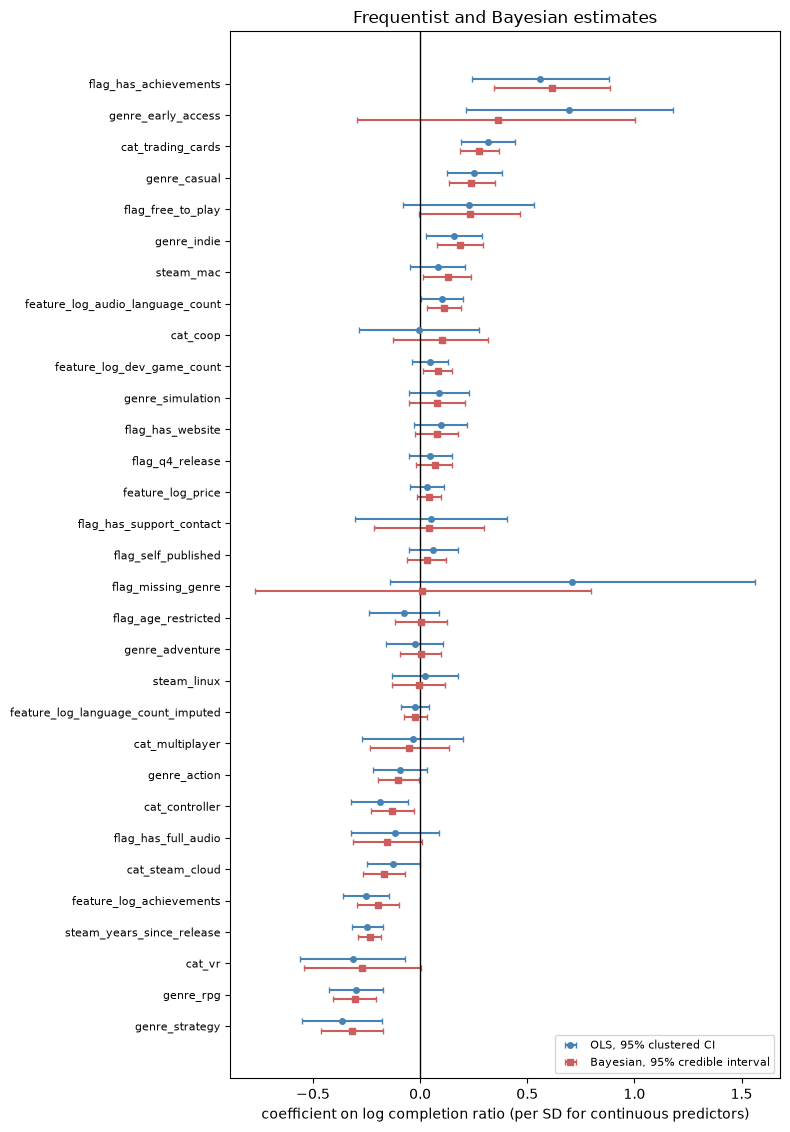

intervals excluding zero: OLS 13, Bayesian 14, both 11


,ols_coef,ols_low,ols_high,bayes_mean,bayes_low,bayes_high,bayes_p_positive,ols_excludes_0,bayes_excludes_0
feature_log_price,0.030,-0.049,0.109,0.040,-0.017,0.096,0.916,False,False
flag_free_to_play,0.226,-0.079,0.531,0.231,-0.006,0.464,0.972,False,False
steam_years_since_release,-0.246,-0.317,-0.175,-0.235,-0.288,-0.182,0.000,True,True
flag_q4_release,0.048,-0.052,0.148,0.067,-0.020,0.151,0.936,False,False
steam_mac,0.082,-0.046,0.211,0.128,0.015,0.239,0.987,False,True
steam_linux,0.025,-0.129,0.178,-0.007,-0.130,0.118,0.446,False,False
feature_log_language_count_imputed,-0.023,-0.090,0.043,-0.022,-0.075,0.032,0.199,False,False
feature_log_audio_language_count,0.101,0.003,0.198,0.110,0.031,0.192,0.998,True,True
flag_has_full_audio,-0.118,-0.324,0.088,-0.153,-0.315,0.007,0.031,False,False
feature_log_achievements,-0.252,-0.360,-0.143,-0.196,-0.296,-0.098,0.000,True,True


In [11]:
beta_draws = np.asarray(idata.posterior["beta"]).reshape(-1, len(FEATURES))
side = pd.DataFrame({
    "ols_coef": ols.params[FEATURES], "ols_low": ci.loc[FEATURES, 0], "ols_high": ci.loc[FEATURES, 1],
    "bayes_mean": beta_draws.mean(0), "bayes_low": np.quantile(beta_draws, 0.025, axis=0),
    "bayes_high": np.quantile(beta_draws, 0.975, axis=0),
    "bayes_p_positive": (beta_draws > 0).mean(0),
}, index=FEATURES)
side["ols_excludes_0"] = (side["ols_low"] > 0) | (side["ols_high"] < 0)
side["bayes_excludes_0"] = (side["bayes_low"] > 0) | (side["bayes_high"] < 0)
side.to_csv(config.TABLES / "03_aq2_coefficients_side_by_side.csv")

order = side["bayes_mean"].sort_values().index
y = np.arange(len(order))
fig, ax = plt.subplots(figsize=(8, 0.32 * len(order) + 1.5))
ax.errorbar(side.loc[order, "ols_coef"], y + 0.15,
            xerr=[side.loc[order, "ols_coef"] - side.loc[order, "ols_low"], side.loc[order, "ols_high"] - side.loc[order, "ols_coef"]],
            fmt="o", markersize=4, capsize=2, color="steelblue", label="OLS, 95% clustered CI")
ax.errorbar(side.loc[order, "bayes_mean"], y - 0.15,
            xerr=[side.loc[order, "bayes_mean"] - side.loc[order, "bayes_low"], side.loc[order, "bayes_high"] - side.loc[order, "bayes_mean"]],
            fmt="s", markersize=4, capsize=2, color="indianred", label="Bayesian, 95% credible interval")
ax.axvline(0, color="black", linewidth=1)
ax.set_yticks(y); ax.set_yticklabels(order, fontsize=8)
ax.set_xlabel("coefficient on log completion ratio (per SD for continuous predictors)")
ax.set_title("Frequentist and Bayesian estimates")
ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
save_fig(fig, "03_aq2_coefficients_side_by_side")
plt.show()
print(f"intervals excluding zero: OLS {int(side['ols_excludes_0'].sum())}, Bayesian {int(side['bayes_excludes_0'].sum())}, "
      f"both {int((side['ols_excludes_0'] & side['bayes_excludes_0']).sum())}")
side.round(3)

### Interpretation: Frequentist against Bayesian estimates

The two models provide similar estimates for several associations. Game age is -0.246 under OLS and -0.235 under the Bayesian model, RPG is -0.300 and -0.304, and Casual is 0.254 and 0.239. Strategy and trading cards keep the same direction although their Bayesian estimates are closer to zero.

Individual 95% intervals exclude zero for 13 OLS coefficients and 14 Bayesian coefficients, with 11 in common. Mac support, Action and developer game count exclude zero only in the Bayesian model. VR and Early Access only in OLS. These are individual interval comparisons. Linux, age restriction, co-op and Adventure change sign, but their intervals include zero under both models, so those sign changes provide little evidence of a substantive disagreement.

Early Access falls from 0.696 to 0.362 and has a wide Bayesian interval of -0.296 to 1.003. The missing-genre estimate falls from 0.711 to 0.011, along with uncertainty in both models. Bayesian intervals are narrower usually, however Early Access and VR intervals are wider. Since there is difference in priors, treatment of developers and poll-dependent noise, this cannot explain which change results in the difference. The intervals also have different meanings. Bayesian intervals describe posterior uncertainty given the model and priors, while confidence intervals describe a procedure's coverage over repeated samples.

## 6. Is there predictive signal?
*Code: Generated by AI Assistant*

*Written by AI Assistant*: every model is scored on the same validation games, which none of them saw in fitting. The baseline predicts the training mean of the log ratio for every game. Metrics, all on the log scale:

- RMSE and MAE of the prediction.
- `R2_vs_baseline` = 1 - (model squared error / baseline squared error). Above 0 means the model beats the baseline out of sample.
- `typical_factor_error` = exp(median absolute error): the factor by which a typical prediction misses the true ratio.
- Coverage and width of a 90% prediction interval. OLS uses its prediction interval, the Bayesian model its posterior predictive interval, which includes each game's poll noise. A calibrated interval covers about 90%.

The RMSE difference from the baseline gets a 95% bootstrap interval; a negative difference means lower error. The bootstrap resamples developers rather than games, because games from one developer are not independent. 2,000 resamples, seeded.

The bootstrap resamples validation developers while holding the trained models fixed. It reflects uncertainty across the observed validation developer groups, not the additional variability of refitting on new training samples. Bayesian interval coverage below refers to the current implementation, which omits new-developer random-effect variation for unseen developers.

In [12]:
def flat(name):
    """Posterior draws with chains stacked: (draws, values)."""
    a = np.asarray(idata.posterior[name])
    return a.reshape(a.shape[0] * a.shape[1], -1)

draws = {k: flat(k) for k in ["intercept", "beta", "sigma", "tau", "sigma_dev", "z_dev"]}
dev_effect = draws["sigma_dev"] * draws["z_dev"]                          # draws x developers
u_val = np.where(dev_val >= 0, dev_effect[:, np.clip(dev_val, 0, None)], 0.0)
mu_val = draws["intercept"] + draws["beta"] @ X_val.to_numpy().T + u_val   # draws x games
noise_val = np.sqrt(draws["sigma"] ** 2 + draws["tau"] ** 2 * inv_polls_val[None, :])
pp_val = mu_val + rng.standard_normal(mu_val.shape) * noise_val

ols_pred = ols.get_prediction(Xc_val).summary_frame(alpha=0.10)
preds = pd.DataFrame({
    "steam_appid": val["steam_appid"].to_numpy(),
    "developer_group": val["developer_group"].to_numpy(),
    "observed": y_val,
    "baseline": np.full(len(y_val), y_train.mean()),
    "ols": ols_pred["mean"].to_numpy(),
    "ols_low": ols_pred["obs_ci_lower"].to_numpy(), "ols_high": ols_pred["obs_ci_upper"].to_numpy(),
    "bayes": mu_val.mean(0),
    "bayes_low": np.quantile(pp_val, 0.05, axis=0), "bayes_high": np.quantile(pp_val, 0.95, axis=0),
    "developer_seen": dev_val >= 0,
})

def score(pred, low=None, high=None):
    err = preds["observed"] - pred
    out = {"RMSE": np.sqrt(np.mean(err ** 2)), "MAE": np.mean(np.abs(err)),
           "R2_vs_baseline": 1 - np.sum(err ** 2) / np.sum((preds["observed"] - preds["baseline"]) ** 2),
           "typical_factor_error": np.exp(np.median(np.abs(err)))}
    if low is not None:
        out["coverage_90"] = np.mean((preds["observed"] >= low) & (preds["observed"] <= high))
        out["mean_interval_width"] = np.mean(high - low)
    return out

comparison = pd.DataFrame({
    "Baseline (training mean)": score(preds["baseline"]),
    "OLS": score(preds["ols"], preds["ols_low"], preds["ols_high"]),
    "Bayesian hierarchical": score(preds["bayes"], preds["bayes_low"], preds["bayes_high"]),
}).T
comparison.insert(0, "validation_games", len(preds))
comparison.to_csv(config.TABLES / "03_aq2_validation_comparison.csv")
print("Bayesian model converged:", bayes_ok)
comparison.round(4)

Bayesian model converged: True


,validation_games,RMSE,MAE,R2_vs_baseline,typical_factor_error,coverage_90,mean_interval_width
Baseline (training mean),482,1.1210,0.8263,0.0000,1.8581,NaN,NaN
OLS,482,1.0437,0.7453,0.1332,1.7409,0.8963,3.3323
Bayesian hierarchical,482,1.0308,0.7298,0.1544,1.7170,0.8859,3.0465


In [13]:
# Developer-level bootstrap of the RMSE gain over the baseline, and of Bayesian against OLS
B = 2000
sq = pd.DataFrame({m: (preds["observed"] - preds[m]) ** 2 for m in ["baseline", "ols", "bayes"]})
sq["dev"] = preds["developer_group"].to_numpy()
per_dev = sq.groupby("dev").agg(["sum", "count"])
sums = {m: per_dev[(m, "sum")].to_numpy() for m in ["baseline", "ols", "bayes"]}
counts = per_dev[("baseline", "count")].to_numpy()

boot = {"OLS - baseline": [], "Bayesian - baseline": [], "Bayesian - OLS": []}
for _ in range(B):
    idx = rng.integers(0, len(counts), len(counts))
    n = counts[idx].sum()
    rmse = {m: np.sqrt(sums[m][idx].sum() / n) for m in sums}
    boot["OLS - baseline"].append(rmse["ols"] - rmse["baseline"])
    boot["Bayesian - baseline"].append(rmse["bayes"] - rmse["baseline"])
    boot["Bayesian - OLS"].append(rmse["bayes"] - rmse["ols"])

point = {"OLS - baseline": comparison.loc["OLS", "RMSE"] - comparison.loc["Baseline (training mean)", "RMSE"],
         "Bayesian - baseline": comparison.loc["Bayesian hierarchical", "RMSE"] - comparison.loc["Baseline (training mean)", "RMSE"],
         "Bayesian - OLS": comparison.loc["Bayesian hierarchical", "RMSE"] - comparison.loc["OLS", "RMSE"]}
boot_table = pd.DataFrame({
    k: {"rmse_difference": point[k], "ci_2.5%": np.quantile(v, 0.025), "ci_97.5%": np.quantile(v, 0.975),
        "share_of_resamples_below_0": np.mean(np.array(v) < 0)}
    for k, v in boot.items()}).T
boot_table.to_csv(config.TABLES / "03_aq2_rmse_bootstrap.csv")
print(f"{len(counts):,} validation developers resampled, {B:,} times. A negative difference means the first model has lower error.")
boot_table.round(4)

414 validation developers resampled, 2,000 times. A negative difference means the first model has lower error.


,rmse_difference,ci_2.5%,ci_97.5%,share_of_resamples_below_0
OLS - baseline,-0.0773,-0.1141,-0.0443,1.000
Bayesian - baseline,-0.0902,-0.1351,-0.0443,1.000
Bayesian - OLS,-0.0129,-0.0389,0.0142,0.847


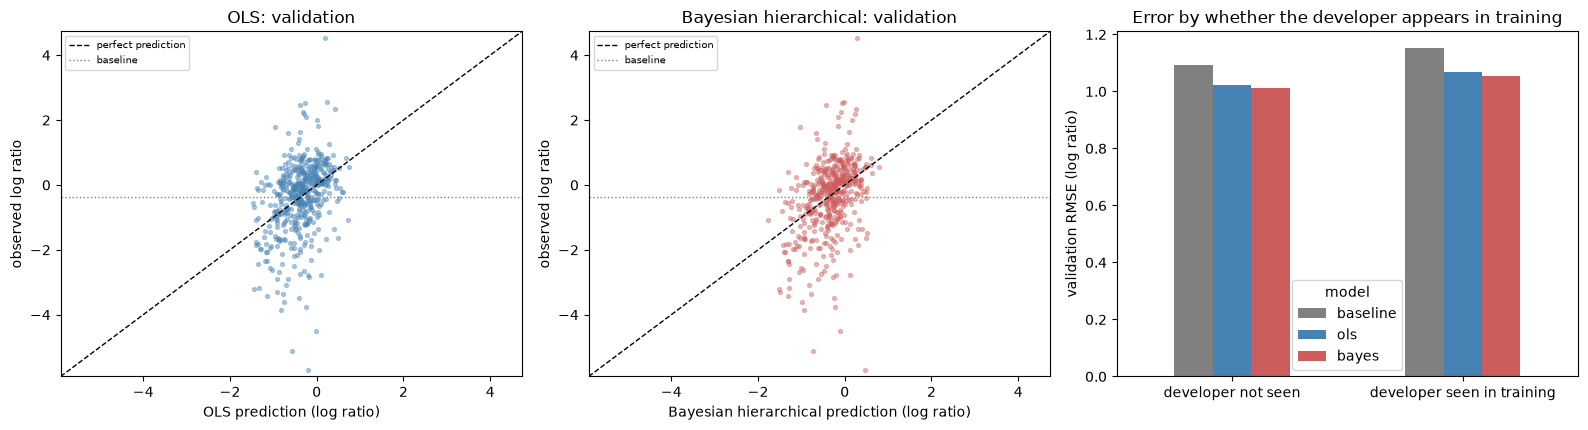

model,baseline,ols,bayes,games
group,,,,
developer not seen,1.0944,1.0242,1.0113,267
developer seen in training,1.1532,1.0675,1.0545,215


In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
lims = [preds["observed"].min() - 0.2, preds["observed"].max() + 0.2]
for ax, (col, label, colour) in zip(axes[:2], [("ols", "OLS", "steelblue"), ("bayes", "Bayesian hierarchical", "indianred")]):
    ax.scatter(preds[col], preds["observed"], s=8, alpha=0.4, color=colour)
    ax.plot(lims, lims, color="black", linestyle="--", linewidth=1, label="perfect prediction")
    ax.axhline(y_train.mean(), color="grey", linestyle=":", linewidth=1, label="baseline")
    ax.set_xlim(lims); ax.set_ylim(lims)
    ax.set_xlabel(f"{label} prediction (log ratio)"); ax.set_ylabel("observed log ratio")
    ax.set_title(f"{label}: validation"); ax.legend(fontsize=7)

seen = preds["developer_seen"]
groups = {"developer seen in training": seen, "developer not seen": ~seen}
rows = []
for g, mask in groups.items():
    for col in ["baseline", "ols", "bayes"]:
        rows.append({"group": g, "model": col, "RMSE": np.sqrt(np.mean((preds.loc[mask, "observed"] - preds.loc[mask, col]) ** 2)),
                     "games": int(mask.sum())})
by_seen = pd.DataFrame(rows).pivot(index="group", columns="model", values="RMSE")[["baseline", "ols", "bayes"]]
by_seen.plot.bar(ax=axes[2], color=["grey", "steelblue", "indianred"], rot=0)
axes[2].set_ylabel("validation RMSE (log ratio)"); axes[2].set_xlabel("")
axes[2].set_title("Error by whether the developer appears in training")
plt.tight_layout()
save_fig(fig, "03_aq2_validation")
plt.show()
by_seen.assign(games=[int(groups[g].sum()) for g in by_seen.index]).round(4)

### Interpretation: Is there predictive signal? (AQ2)

Both models show better prediction of the completion-ratio proxy than the baseline mean on validation games. Across the 482 games, RMSE falls from 1.1210 for the training-mean baseline to 1.0437 for OLS and 1.0308 for the Bayesian model. The `R2_vs_baseline` values of 0.1332 and 0.1544 represent reductions of 13.

The bootstrap results also support the improvement over the baseline. The 95% interval for OLS minus baseline RMSE is [-0.1141, -0.0443], and the Bayesian interval is [-0.1351, -0.0443]. Both are entirely below zero. The difference between the two models is not as clear. Bayesian minus OLS RMSE is -0.0129, with an interval of [-0.0389, 0.0142]. Because this includes zero, there is a lack of sufficient evidence here to claim that the Bayesian model predicts better than OLS.

Individual predictions still have considerable error. MAE is 0.7453 for OLS and 0.7298 for Bayesian regression, compared with 0.8263 for the baseline. 

The nominal 90% intervals cover 89.6% of validation games for OLS and 88.6% for the Bayesian model. The mean widths are 3.3323 and 3.0465 log units. Bayesian intervals are slightly narrower, along with slightly lower coverage. 

The small Bayesian improvement appears in both developer groups. RMSE is 1.0545 versus 1.0675 for OLS among the 215 games from seen developers, and 1.0113 versus 1.0242 among the 267 games from unseen developers, although what causes this improvement is unexplained. Overall, the evidence supports predictive value the selected completion-ratio sample, with substantial uncertainty for any one game. It ultimately does not establish the ability to predict sales or profitability.

### Validation calibration
*Code: Generated by AI Assistant, adapted from Sheen Fernando's diagnostics in `notebooks/archive/03_aq2_reception_models.ipynb`*

*Written by AI Assistant*: The decile check adapted from the archived diagnostics. Validation games are grouped into tenths by predicted log ratio, separately for each model, and the mean prediction in each group is plotted against the mean observed log ratio. Points on the diagonal mean the model's predictions are right on average at that level. A flat observed-mean line would suggest little separation across prediction groups; it is not a formal comparison of predictive error against the baseline.

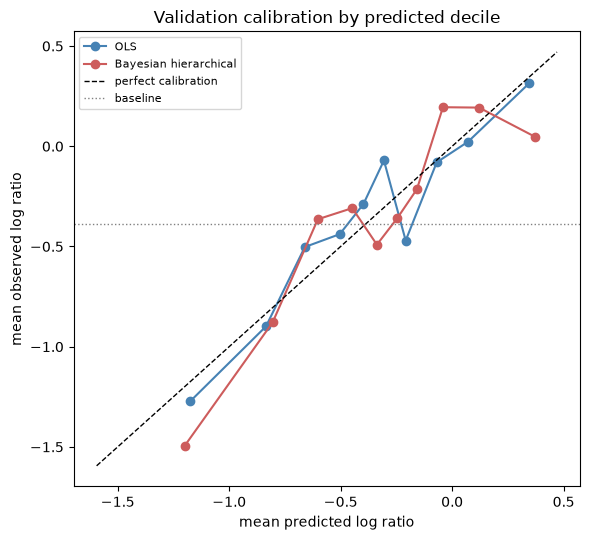

mean_predicted                mean_observed       
model  Bayesian hierarchical    OLS Bayesian hierarchical    OLS
decile                                                          
0                     -1.199 -1.174                -1.494 -1.272
1                     -0.805 -0.835                -0.879 -0.899
2                     -0.602 -0.661                -0.364 -0.503
3                     -0.448 -0.504                -0.309 -0.438
4                     -0.337 -0.398                -0.491 -0.288
5                     -0.246 -0.306                -0.359 -0.071
6                     -0.158 -0.208                -0.214 -0.470
7                     -0.041 -0.069                 0.195 -0.080
8                      0.121  0.072                 0.193  0.023
9                      0.370  0.346                 0.048  0.315

In [15]:
rows = []
for col, label in [("ols", "OLS"), ("bayes", "Bayesian hierarchical")]:
    decile = pd.qcut(preds[col], 10, labels=False, duplicates="drop")
    g = preds.groupby(decile).agg(games=("observed", "size"), mean_predicted=(col, "mean"), mean_observed=("observed", "mean"))
    rows.append(g.assign(model=label))
calibration = pd.concat(rows).rename_axis("decile").reset_index()
calibration.to_csv(config.TABLES / "03_aq2_validation_calibration.csv", index=False)

fig, ax = plt.subplots(figsize=(6, 5.5))
for (label, g), colour in zip(calibration.groupby("model", sort=False), ["steelblue", "indianred"]):
    ax.plot(g["mean_predicted"], g["mean_observed"], marker="o", color=colour, label=label)
lo = calibration[["mean_predicted", "mean_observed"]].min().min() - 0.1
hi = calibration[["mean_predicted", "mean_observed"]].max().max() + 0.1
ax.plot([lo, hi], [lo, hi], color="black", linestyle="--", linewidth=1, label="perfect calibration")
ax.axhline(y_train.mean(), color="grey", linestyle=":", linewidth=1, label="baseline")
ax.set_xlabel("mean predicted log ratio"); ax.set_ylabel("mean observed log ratio")
ax.set_title("Validation calibration by predicted decile"); ax.legend(fontsize=8)
plt.tight_layout()
save_fig(fig, "03_aq2_validation_calibration")
plt.show()
calibration.pivot(index="decile", columns="model", values=["mean_predicted", "mean_observed"]).round(3)

### Interpretation: Validation calibration

Generally, both models provide higher predictions to groups with higher observed log ratios, however the calibration is uneven. Several observed means deviate from the diagonal, and they do not increase consistently from one decile to the next.

Each group only contains 48-49 games, and each model puts different games into their deciles. Without uncertainty bands, individual bends in the plot should not be taken as firm evidence of systematic bias.

## Save for later stages
*Code: Generated by AI Assistant*

*Written by AI Assistant*: validation predictions from all three models are saved for AQ3 onwards. The fitted OLS coefficients and Bayesian summaries are written to `outputs/tables`; trace export is optional and failed in the saved run because its NetCDF backend was unavailable. No rows are filtered here beyond the modelling sample in section 1.

In [16]:
preds.to_parquet(config.INTERIM / "03_aq2_predictions.parquet", index=False)
print(f"rows out: {len(preds):,} validation predictions -> data/interim/03_aq2_predictions.parquet")
print(f"figures: {sorted(p.name for p in config.FIGURES.glob('03_aq2_*.png'))}")
print(f"tables : {sorted(p.name for p in config.TABLES.glob('03_aq2_*.csv'))}")

rows out: 482 validation predictions -> data/interim/03_aq2_predictions.parquet
figures: ['03_aq2_coefficients_side_by_side.png', '03_aq2_ols_diagnostics.png', '03_aq2_posterior_predictive.png', '03_aq2_prior_predictive.png', '03_aq2_target.png', '03_aq2_validation.png', '03_aq2_validation_calibration.png']
tables : ['03_aq2_bayes_summary.csv', '03_aq2_coefficients_side_by_side.csv', '03_aq2_influence_refits.csv', '03_aq2_ols_coefficients.csv', '03_aq2_prior_sensitivity.csv', '03_aq2_rmse_bootstrap.csv', '03_aq2_validation_calibration.csv', '03_aq2_validation_comparison.csv', '03_aq2_vif.csv']
